In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [7]:
df = pd.read_csv(r'C:\Users\rohansha\OneDrive - Capgemini\Documents\ML\Function Transformer\Titanic-Dataset.csv', usecols = ['Age', 'Fare', 'Survived'])

In [4]:
import os
print(os.getcwd())

C:\Users\rohansha\OneDrive - Capgemini\Documents\ML\Encoding Numerical Features


In [8]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [9]:
 df.dropna(inplace = True)

In [10]:
df.shape

(714, 3)

In [11]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =0.2, random_state = 42)

In [13]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [14]:
clf = DecisionTreeClassifier()

In [15]:
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

In [16]:
accuracy_score(y_test, y_pred)

0.6363636363636364

In [17]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y ,cv=10,scoring ='accuracy'))

np.float64(0.63589593114241)

In [38]:
kbin_age = KBinsDiscretizer(n_bins =15, strategy='quantile',encode ='ordinal')
kbin_fare = KBinsDiscretizer(n_bins =15, encode = 'ordinal', strategy = 'quantile')

In [39]:
trf = ColumnTransformer([
    ('first', kbin_age,[0]),
    ('second', kbin_fare, [1])
])

In [40]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


In [41]:
trf.named_transformers_['first'].n_bins_

array([15])

In [42]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [43]:
output = pd.DataFrame({
    'age': X_train['Age'],
    'age_trf' : X_train_trf[:,0],
    'fare': X_train['Fare'],
    'fare_trf': X_train_trf[:,1]
})

In [44]:
output['age_labels'] = pd.cut(x =X_train['Age'], bins= trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x = X_train['Fare'], bins = trf.named_transformers_['second'].bin_edges_[0].tolist())

In [45]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
731,11.0,1.0,18.7875,8.0,"(6.0, 16.0]","(18.75, 26.0]"
786,18.0,2.0,7.4958,1.0,"(16.0, 19.0]","(7.25, 7.775]"
474,22.0,4.0,9.8375,4.0,"(21.0, 23.0]","(8.158, 10.5]"
110,47.0,13.0,52.0000,12.0,"(42.0, 47.0]","(51.479, 76.292]"
205,2.0,0.0,10.4625,4.0,"(0.42, 6.0]","(8.158, 10.5]"


In [46]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf, y_train)
y_pred2 = clf.predict(X_test_trf)

In [47]:
accuracy_score(y_test, y_pred2)

0.6363636363636364

In [48]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(), X, y ,cv =10, scoring ='accuracy'))

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


np.float64(0.6386737089201878)

In [55]:
def discretize(bins, strategy):
        kbin_age = KBinsDiscretizer(n_bins = bins, encode = 'ordinal', strategy = strategy)
        kbin_fare = KBinsDiscretizer(n_bins = bins, encode = 'ordinal', strategy = strategy)

        trf = ColumnTransformer([
            ('first', kbin_age, [0]),
            ('second', kbin_fare, [1])
        ])

        X_trf = trf.fit_transform(X)
        print(np.mean(cross_val_score(DecisionTreeClassifier(), X, y, cv=10, scoring = 'accuracy')))

        plt.figure(figsize =(14,4))
        plt.subplot(121)
        plt.hist(X['Age'])
        plt.title("Before")

        plt.subplot(122)
        plt.hist(X_trf[:,0], color ='red')
        plt.title('After')

        plt.show()

        plt.figure(figsize =(14,4))
        plt.subplot(121)
        plt.hist(X['Fare'])
        plt.title("Before")

        plt.subplot(122)
        plt.hist(X_trf[:,1], color ='red')
        plt.title('After')

        plt.show()

    

C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
C:\Users\rohansha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


0.6289123630672927


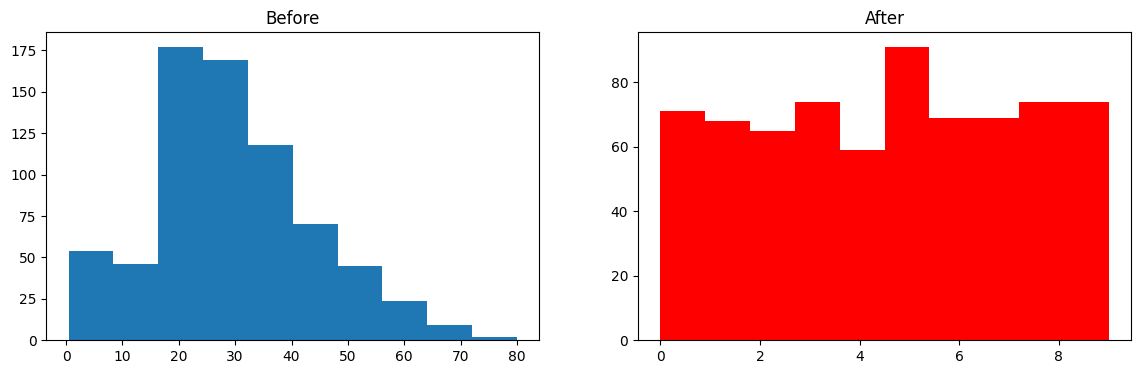

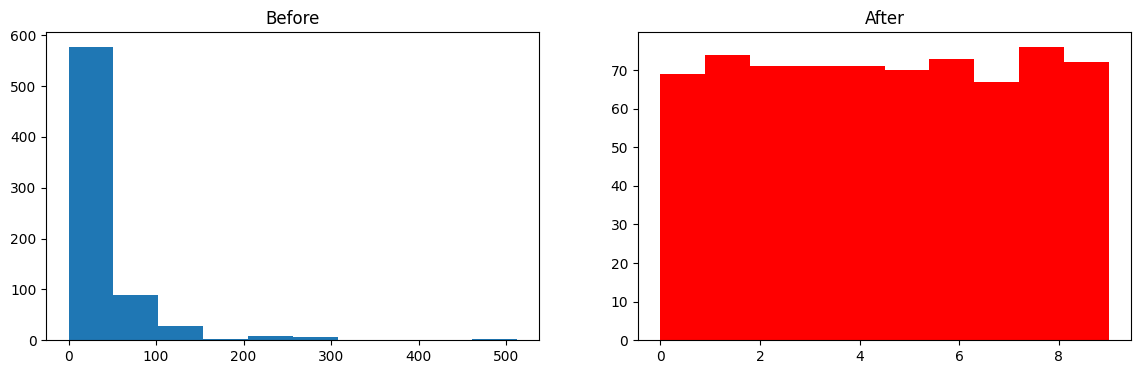

In [56]:
discretize(10,'quantile')

0.6358959311424099


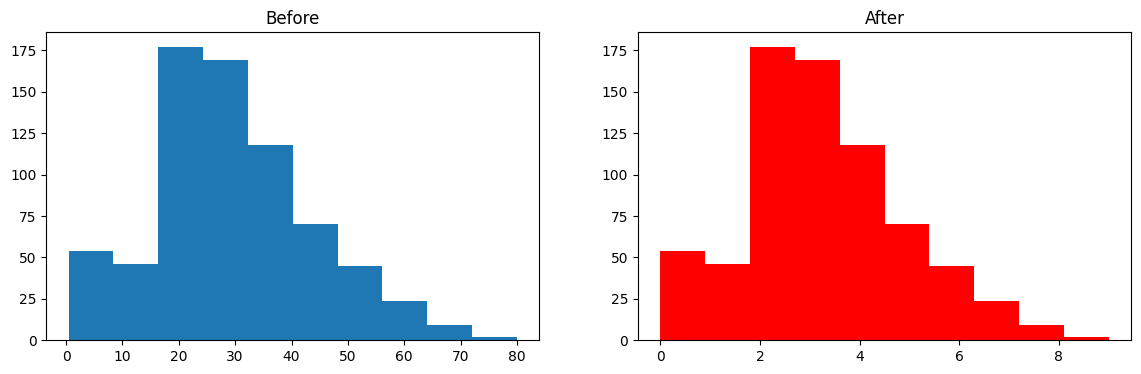

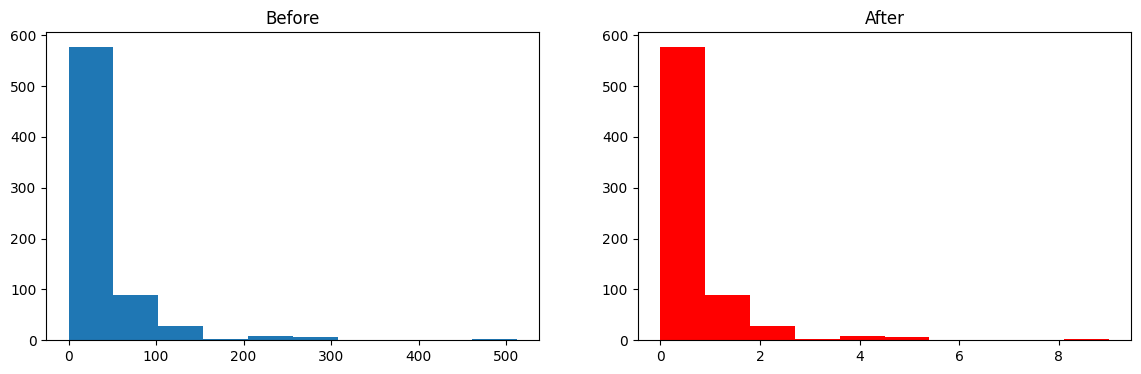

In [57]:
discretize(10,'uniform')